In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams.update({'errorbar.capsize': 3})
plt.rcParams['xtick.labelsize']= 13
plt.rcParams['ytick.labelsize']= 13
plt.rcParams.update({'axes.labelsize': 16})

In [18]:
from astropy.io import fits
from astropy.table import Table

In [3]:
import spectres

In [4]:
import os

In [5]:
import pickle

In [6]:
from sklearn.decomposition import PCA

In [7]:
date="2021/05/30/"


In [8]:
neid_files0=os.listdir('../../data/spectra/NEID/'+ date)
neid_files=[f for f in neid_files0 if f.endswith('.fits')]

date2="2021/05/210530/"
exp_files0=os.listdir('../../data/spectra/EXPRES/'+ date2)
exp_files=[f for f in exp_files0 if f.endswith('.fits')]

# explore NEID

In [9]:
E_wls=[]
with fits.open('../../data/spectra/EXPRES/'+ date2+exp_files[0]) as f:
    data1=f[1].data
    E_wls=data1['wavelength']
    

In [10]:
NEID_wls=[]
with fits.open('../../data/spectra/NEID/'+ date+neid_files[0]) as f:
    f.info()
    dims=f['SCIFLUX'].data.shape
    print(dims)
    for i in range(dims[0]):
        #plt.plot(f['SCIWAVE'].data[i],f['SCIFLUX'].data[i])
        NEID_wls.append(f['SCIWAVE'].data[i])
NEID_wls=np.array(NEID_wls)

Filename: ../../data/spectra/NEID/2021/05/30/neidL2_20210530T200738.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU     828   ()      
  1  SCIFLUX       1 ImageHDU        13   (9216, 122)   float64   
  2  SKYFLUX       1 ImageHDU        13   (9216, 122)   float64   
  3  CALFLUX       1 ImageHDU        13   (9216, 122)   float64   
  4  SCIVAR        1 ImageHDU        12   (9216, 122)   float32   
  5  SKYVAR        1 ImageHDU        12   (9216, 122)   float32   
  6  CALVAR        1 ImageHDU        12   (9216, 122)   float32   
  7  SCIWAVE       1 ImageHDU      2451   (9216, 122)   float64   
  8  SKYWAVE       1 ImageHDU      2451   (9216, 122)   float64   
  9  CALWAVE       1 ImageHDU      2451   (9216, 122)   float64   
 10  TELLURIC      1 ImageHDU        20   (2, 9216, 122)   float64   
 11  SKY           1 ImageHDU         8   ()      
 12  CCFS          1 ImageHDU       531   (804, 122)   float64   
 13  ACTIVITY      1 Bin

(3800.0, 8500.0)

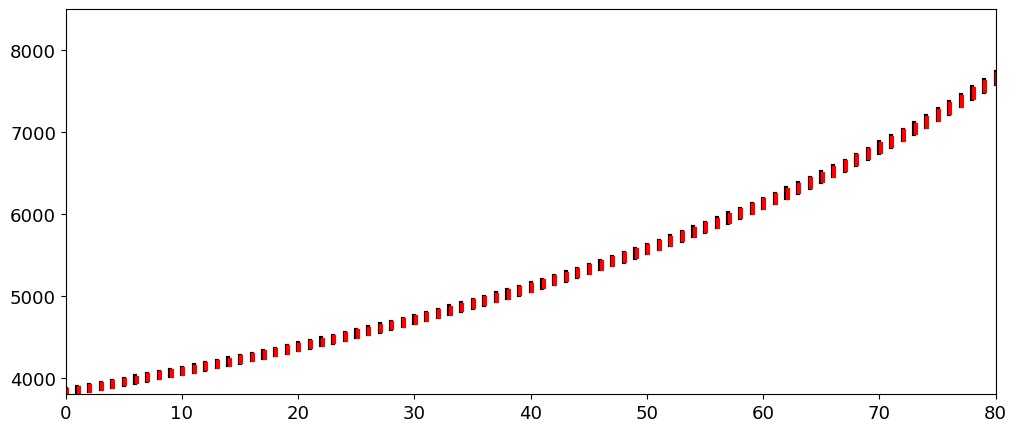

In [11]:
for i,item in enumerate(NEID_wls[13:13+84]):
    plt.plot([i,i],[item[0],item[-1]],color='k',lw=3)
for i,item in enumerate(E_wls):
    plt.plot([i+.1,i+.1],[item[0],item[-1]],color='r',lw=3)
plt.xlim(0,80)
plt.ylim(3800,8500)

In [16]:
#for each order, find the center wavelength of the order and compare it to the center wavlength of the EXPRES orders. of the order of the other instrument
cens=[]
for i,item in enumerate(NEID_wls[13:13+86]):
    E_w=E_wls[i]
    N_w=item
    cens.append((np.median(N_w), np.median(E_w)))
    print(np.median(N_w),np.median(E_w), abs(np.median(N_w)-np.median(E_w)), (abs(np.median(N_w)-np.median(E_w))/np.median(N_w))*100)
    #print the center wavelengths, their difference and the % difference 
    #print((N_w[0]+N_w[-1])/2, (E_w[0]+E_w[-1])/2, abs((N_w[0]+N_w[-1])/2 - (E_w[0]+E_w[-1])/2), (abs((N_w[0]+N_w[-1])/2 - (E_w[0]+E_w[-1])/2)/((N_w[0]+N_w[-1])/2))*100)


3836.416196409954 3828.646074592197 7.770121817757172 0.20253594552719034
3860.5460744860984 3852.757949911168 7.788124574930407 0.20173634570511204
3884.9810811654725 3877.174498945352 7.806582220120617 0.2009426058203271
3909.7272569106644 3901.901559627491 7.825697283173213 0.20015967275826846
3934.790924930642 3926.945118912487 7.845806018155145 0.19939575362046563
3960.177825851679 3952.31131757269 7.866508278988931 0.19864027891972638
3985.8945709101677 3978.0064551880487 7.888115722118982 0.1979007618437272
4011.9470378760034 4004.036995339105 7.910042536898345 0.19716218739233565
4038.342658286766 4030.409571011177 7.93308727558906 0.19644413431114355
4065.0874505292913 4057.130990218717 7.95646031057413 0.19572667027220203
4092.189524003228 4084.20824185926 7.981282143968201 0.1950369624171372
4119.654541181856 4111.648501806987 8.006039374869033 0.19433763911117272
4147.491337550397 4139.459139256553 8.032198293843976 0.19366401615170042
4175.706531399522 4167.647723328373 8.

In [19]:
orders=np.arange(len(cens))
#create a table of orders with median wavlengths and write the table to a file
#using astropy.table
table=Table([orders, [c[0] for c in cens], [c[1] for c in cens]], names=['order', 'NEID_wl_center', 'EXPRES_wl_center'])
table.write('wavelength_centers.csv', format='csv')

In [17]:
cens

[(np.float64(3836.416196409954), np.float64(3828.646074592197)),
 (np.float64(3860.5460744860984), np.float64(3852.757949911168)),
 (np.float64(3884.9810811654725), np.float64(3877.174498945352)),
 (np.float64(3909.7272569106644), np.float64(3901.901559627491)),
 (np.float64(3934.790924930642), np.float64(3926.945118912487)),
 (np.float64(3960.177825851679), np.float64(3952.31131757269)),
 (np.float64(3985.8945709101677), np.float64(3978.0064551880487)),
 (np.float64(4011.9470378760034), np.float64(4004.036995339105)),
 (np.float64(4038.342658286766), np.float64(4030.409571011177)),
 (np.float64(4065.0874505292913), np.float64(4057.130990218717)),
 (np.float64(4092.189524003228), np.float64(4084.20824185926)),
 (np.float64(4119.654541181856), np.float64(4111.648501806987)),
 (np.float64(4147.491337550397), np.float64(4139.459139256553)),
 (np.float64(4175.706531399522), np.float64(4167.647723328373)),
 (np.float64(4204.308529255015), np.float64(4196.2220299473465)),
 (np.float64(4233.3